<div id="introduction">
    <h1>P2: EKF-Enhanced MPC for a DC Motor</h1>
    <h2>Implement an Extended Kalman Filter (EKF) for state estimation and kalman Filtering</h2>
    
<p>
        In this notebook, I implement and evaluate an <strong>Extended Kalman Filter (EKF)</strong> designed to estimate the states of a nonlinear DC motor system. The primary challenge of this task is that while angular velocity $\omega(t)$ is measured, the armature current $i_a(t)$ is not. Furthermore, the system is inherently nonlinear due to the product of the field current input $u(t)$ and the system states.
    </p>

<h3>Objective</h3>
    <p>
        The goal of this specific study is to determine which numerical discretization method provides the most reliable foundation for the EKF. Since the motor will eventually be controlled by a Nonlinear MPC, the state estimates must be both accurate and stable to avoid violating physical constraints.
    </p>

<h3>Methodology: The Discretization Benchmark</h3>
    <p>
        I have implemented the EKF using seven different discretization techniques to analyze their impact on estimation performance:
    </p>
    <ul>
        <li>Forward Euler Method (FED)</li>
        <li>Backward Euler Method (BED)</li>
        <li>Runge-Kutta 4th Order (RK4)</li>
        <li>Heun's Method (Improved Euler)</li>
        <li>Orthogonal Collocation on Finite Elements</li>
        <li>Tustin’s Method (Bilinear Transformation)</li>
        <li>Zero-Order Hold (ZOH) Approximation</li>
    </ul>

<p>
        Each method is evaluated using a fixed sampling time of $\Delta t = 0.05$ s. To make an evidence-based selection for the "best" method, I am tracking two key performance metrics for the unmeasured state ($i_a$):
    </p>
    <ul>
        <li><strong>Root Mean Square Error (RMSE):</strong> To measure overall estimation accuracy and noise suppression.</li>
        <li><strong>Max Error:</strong> To identify which methods are prone to unstable "spikes" during sudden transients.</li>
    </ul>
    
<hr>
</div>

<div id="ekf-implementation">
<h1>Extended Kalman Filter (EKF) Implementation</h1>

<p>
In this section, I develop the core <strong>Extended Kalman Filter (EKF)</strong> logic. The goal is to provide reliable state estimates by linearizing the nonlinear DC motor dynamics at each time step. This implementation specifically focuses on the <strong>Forward Euler Discretization</strong> as a baseline for the benchmark study.
</p>

<h3>1. System Configuration & Constants</h3>
<p>
The motor parameters are initialized according to the provided specifications. Key physical constants include:
</p>
<ul>
<li><strong>Armature Resistance ($R_a$):</strong> $12.345 \, \Omega$ </li>
<li><strong>Armature Inductance ($L_a$):</strong> $0.314 \, H$ </li>
<li><strong>Motor Constant ($k_m$):</strong> $0.253 \, Nm/A^2$ </li>
<li><strong>Sampling Time ($\Delta t$):</strong> $0.05 \, s$ </li>
</ul>

<h3>2. Symbolic Modeling with CasADi</h3>
<p>
To automate the linearization process required by the EKF, I use <strong>CasADi</strong> to define the symbolic state-space model.
</p>
<ul>
<li><strong>State Vector ($x$):</strong> Includes armature current ($i_a$) and angular velocity ($\omega$).</li>
<li><strong>Input ($u$):</strong> Defined as the field current ($i_f$).</li>
<li><strong>Jacobians ($A, C$):</strong> Computed automatically using symbolic differentiation to represent the linearized system dynamics and measurement models.</li>
</ul>

<h3>3. EKF Algorithmic Flow</h3>

<p>
The filter is implemented as a discrete recursive function that executes two primary phases per sampling interval:
</p>
<ul>
<li><strong>Correction Step:</strong> Updates the state estimate based on the residual between the actual noisy measurement of $\omega$ and the model's prediction.</li>
<li><strong>Prediction Step:</strong> Projects the state and the error covariance forward to the next time step using the discretized nonlinear model.</li>
</ul>

<h3>4. Noise & Uncertainty Handling</h3>
<p>
The filter is tuned using the mandatory noise statistics defined in the project description:
</p>
<ul>
<li><strong>Process Noise ($Q$):</strong> $\text{diag}(0.01, 100.0)$ for current and velocity fluctuations.</li>
<li><strong>Measurement Noise ($R$):</strong> $1.0$ for the velocity sensor.</li>
<li><strong>Initial Covariance ($P_0$):</strong> Tuned to reflect initial uncertainty in the motor's state estimates.</li>
</ul>

<p>
The following code block executes the simulation for 10 seconds, utilizing random step inputs within the range of $[-5, 5]$ to test the observer's tracking performance under dynamic conditions.
</p>

<hr>
</div>

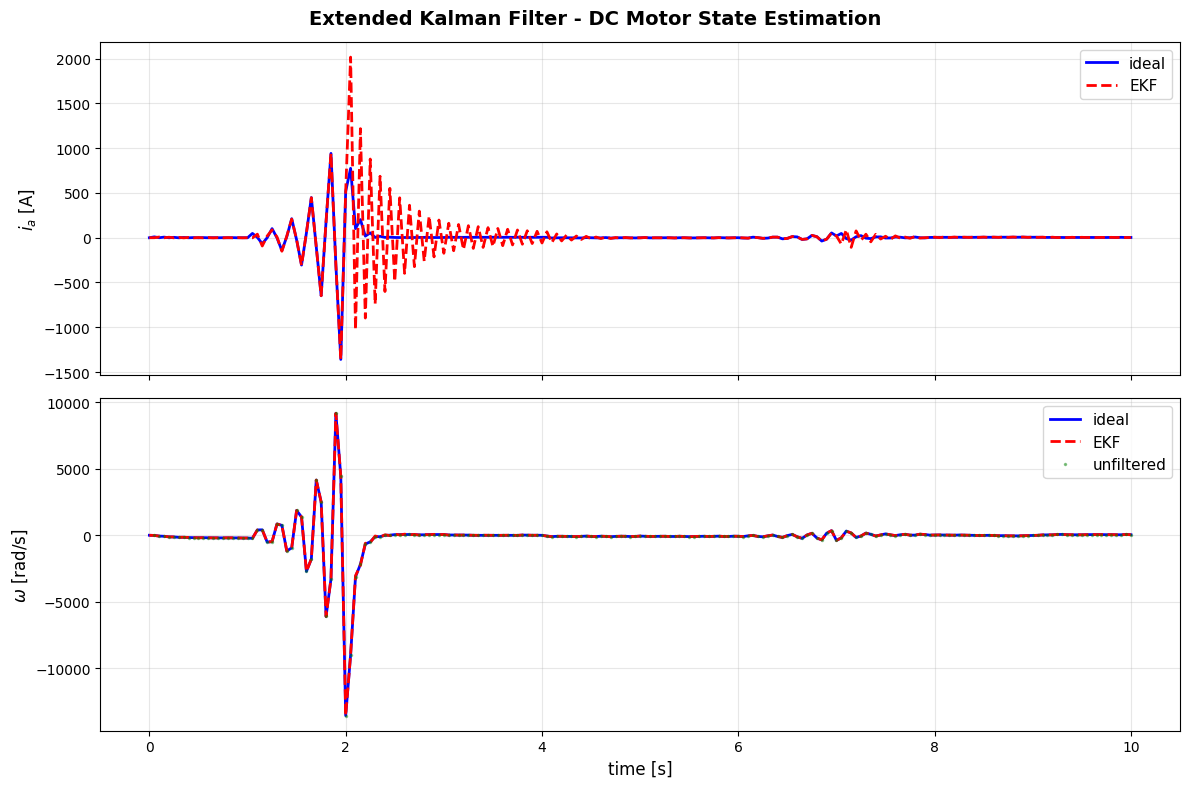

Estimation Performance Metrics:
RMSE (ia):         205.4359 A
RMSE (omega):      12.7060 rad/s
Max error (ia):    1241.9329 A
Max error (omega): 77.3911 rad/s


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from casadi import *

# System Parameters
Ra = 12.345      # Armature resistance [Ω]
La = 0.314       # Armature inductance [H]
km = 0.253       # Motor back-emf constant [Nm/A²]
J = 0.00441      # Total inertia [Nm·s²]
B = 0.00732      # Viscous friction coefficient [Nms]
ua = 60.0        # Constant armature voltage [V]
tau_l = 1.47     # Load torque [Nm]
dt = 0.05        # Sampling time [s]

# Noise statistics
var_v = 1.0      # Measurement noise variance
var_w1 = 0.01    # Process noise variance for ia
var_w2 = 100.0   # Process noise variance for omega

# System dimensions
nx = 2  # States: [ia, omega]
nu = 1  # Inputs: [if]
ny = 1  # Measurements: [omega]

# ----------------------------------------------------------------------------
# System Dynamics and Linearization
# ----------------------------------------------------------------------------

x = SX.sym("x", nx)
u = SX.sym("u", nu)

ia = x[0]
omega = x[1]
u_field = u[0]

# Continuous dynamics
dia_dt = -Ra/La * ia - km/La * omega * u_field + ua/La
domega_dt = -B/J * omega + km/J * ia * u_field - tau_l/J
f_cont = vertcat(dia_dt, domega_dt)

# Discretize (Forward Euler)
x_next = x + dt * f_cont
system = Function('system', [x, u], [x_next])

# Measurement equation
y_k = x[1]
measurement = Function('measurement', [x], [y_k])

# Jacobians for EKF
A_tilde = jacobian(x_next, x)
A_fun = Function('A_fun', [x, u], [A_tilde])

C_tilde = jacobian(y_k, x)
C_fun = Function('C_fun', [x], [C_tilde])

# ----------------------------------------------------------------------------
# EKF Implementation
# ----------------------------------------------------------------------------

def discrete_EKF_filter(x0, x0_observer, P_0, Q, R, N_sim, u_inputs):
    x_data = [x0]
    x_hat_data = [x0_observer]
    y_measured = []
    
    std_x = np.sqrt(Q.diagonal()).reshape(nx, 1)
    std_y = np.sqrt(R)
    
    for k in range(N_sim):
        u_k = u_inputs[k].reshape(nu, 1)
        
        # --- Correction Step ---
        C_k = C_fun(x0_observer).full()
        
        S = C_k @ P_0 @ C_k.T + R
        L = P_0 @ C_k.T @ np.linalg.inv(S)
        
        # Simulate Plant
        wx = np.random.normal(0, std_x).reshape(nx, 1)
        wy = np.random.normal(0, std_y)
        x0 = system(x0, u_k).full() + wx
        y = measurement(x0).full() + wy
        
        # Update State Estimate
        innovation = y - measurement(x0_observer).full()
        x0_observer = x0_observer + L @ innovation
        
        # Update Covariance
        P_0 = (np.eye(nx) - L @ C_k) @ P_0
        
        x_data.append(x0)
        x_hat_data.append(x0_observer)
        y_measured.append(y)
        
        # --- Prediction Step ---
        x0_observer = system(x0_observer, u_k).full()
        A_k = A_fun(x0_observer, u_k).full()
        P_0 = A_k @ P_0 @ A_k.T + Q

    x_data = np.concatenate(x_data, axis=1)
    x_hat_data = np.concatenate(x_hat_data, axis=1)
    y_measured = np.array(y_measured).reshape(1, -1)
    
    return x_data, x_hat_data, y_measured

# ----------------------------------------------------------------------------
# Visualization & Helpers
# ----------------------------------------------------------------------------

def visualize(x_data, x_hat_data, y_measured, time):
    fig, ax = plt.subplots(2, 1, figsize=(12, 8))
    fig.suptitle('Extended Kalman Filter - DC Motor State Estimation', 
                 fontsize=14, fontweight='bold')
    
    # Armature current
    ax[0].plot(time, x_data[0, :], 'b-', linewidth=2, label='ideal')
    ax[0].plot(time, x_hat_data[0, :], 'r--', linewidth=2, label='EKF')
    ax[0].set_ylabel('$i_a$ [A]', fontsize=12)
    ax[0].legend(fontsize=11, loc='best')
    ax[0].grid(True, alpha=0.3)
    ax[0].set_xticklabels([])
    
    # Angular velocity
    ax[1].plot(time, x_data[1, :], 'b-', linewidth=2, label='ideal')
    ax[1].plot(time, x_hat_data[1, :], 'r--', linewidth=2, label='EKF')
    ax[1].plot(time[1:], y_measured[0, :], 'g.', markersize=3, 
               alpha=0.4, label='unfiltered')
    ax[1].set_ylabel('$\omega$ [rad/s]', fontsize=12)
    ax[1].set_xlabel('time [s]', fontsize=12)
    ax[1].legend(fontsize=11, loc='best')
    ax[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('ekf_results_FED.png', dpi=150, bbox_inches='tight')
    plt.show()

def generate_random_step_inputs(N_sim, u_min=-5, u_max=5):
    u_inputs = np.zeros(N_sim)
    step_duration = int(1.0 / dt)
    
    for i in range(0, N_sim, step_duration):
        u_step = np.random.uniform(u_min, u_max)
        u_inputs[i:min(i+step_duration, N_sim)] = u_step
    
    return u_inputs

# ----------------------------------------------------------------------------
# Main Execution
# ----------------------------------------------------------------------------

if __name__ == "__main__":
    np.random.seed(42)
    
    t_sim = 10.0
    N_sim = int(t_sim / dt)
    time = np.arange(N_sim + 1) * dt
    
    # Initial conditions
    x0 = np.array([0.0, 0.0]).reshape([-1, 1])
    x0_observer = np.array([0.0, 0.0]).reshape([-1, 1])
    
    u_inputs = generate_random_step_inputs(N_sim, u_min=-5, u_max=5)
    
    # Covariance Matrices
    Q = np.diag([var_w1, var_w2])
    R = np.array([[var_v]])
    P_0 = np.diag([1.0, 100.0])

    x_data, x_hat_data, y_measured = discrete_EKF_filter(
        x0, x0_observer, P_0, Q, R, N_sim, u_inputs
    )
    
    visualize(x_data, x_hat_data, y_measured, time)
    
    # Calculate errors
    error_ia = x_data[0, :] - x_hat_data[0, :]
    error_omega = x_data[1, :] - x_hat_data[1, :]
    
    print("="*70)
    print("Estimation Performance Metrics:")
    print("="*70)
    print(f"RMSE (ia):         {np.sqrt(np.mean(error_ia**2)):.4f} A")
    print(f"RMSE (omega):      {np.sqrt(np.mean(error_omega**2)):.4f} rad/s")
    print(f"Max error (ia):    {np.max(np.abs(error_ia)):.4f} A")
    print(f"Max error (omega): {np.max(np.abs(error_omega)):.4f} rad/s")
    print("="*70)

<h3>Runge-Kutta 4th Order Discretization</h3>

<p>
    When we deal with a continuous-time system—like the differential equations of our DC motor—we need a way to move from continuous calculus to discrete time steps that a computer can understand. This process is called <strong>discretization</strong>.
</p>

<p>
    The <strong>4th Order Runge-Kutta (RK4)</strong> method is one of the most widely used techniques for this. While simpler methods (like Forward Euler) only look at the slope at the beginning of a time step, RK4 is much more sophisticated. It calculates four different "slopes" (k-values) to get a better sense of where the system is headed:
</p>

<ul>
    <li><strong>k1:</strong> The slope at the beginning of the interval.</li>
    <li><strong>k2:</strong> The slope at the midpoint, using k1 to get there.</li>
    <li><strong>k3:</strong> Another slope at the midpoint, but using k2 to get there.</li>
    <li><strong>k4:</strong> The slope at the end of the interval, using k3 to get there.</li>
</ul>

<p>
    By taking a weighted average of these four slopes, RK4 cancels out lower-order errors. This allows us to use a larger sampling time (like our Δt = 0.05s) while still maintaining a very high level of precision in our state estimation.
</p>

<p>
    <strong>The RK4 Update Formula:</strong><br>
    x(k+1) = x(k) + (Δt / 6) * (k1 + 2*k2 + 2*k3 + k4)
</p>

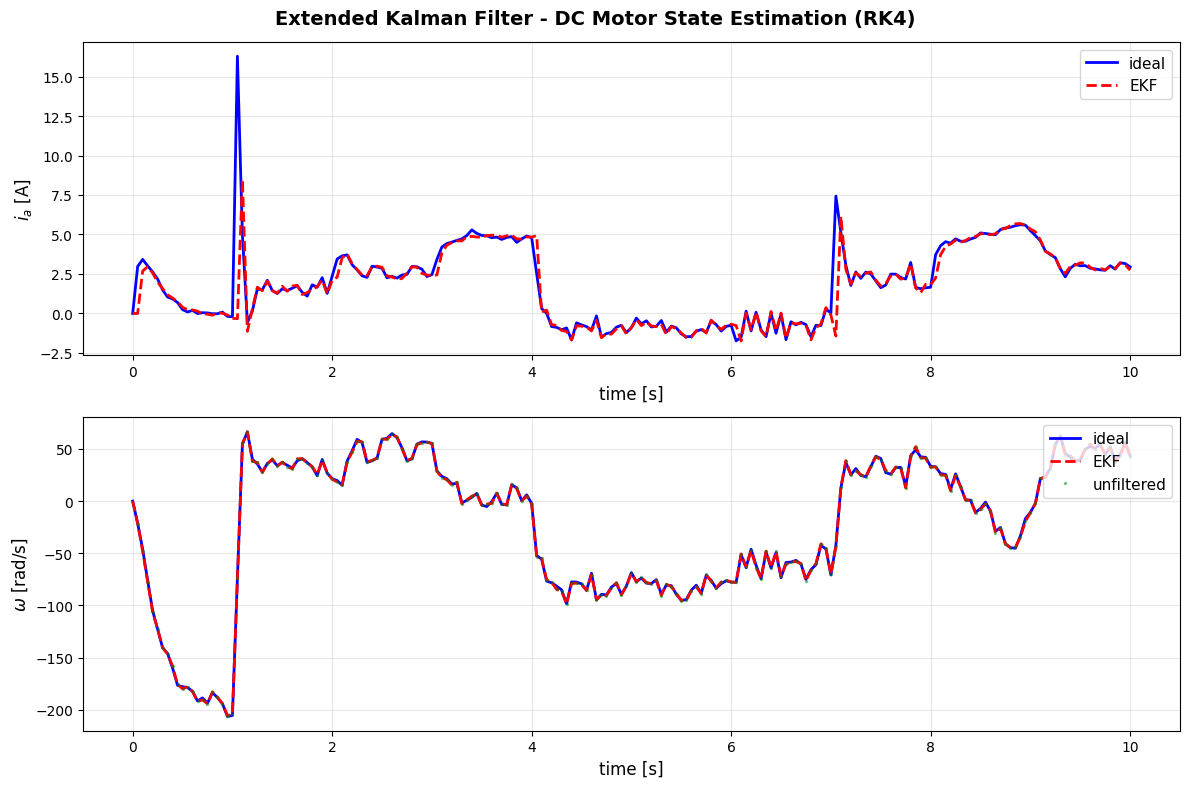

Estimation Performance Metrics:
RMSE (ia):         1.3961 A
RMSE (omega):      1.0014 rad/s
Max error (ia):    16.6155 A
Max error (omega): 3.2033 rad/s


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from casadi import *

# ----------------------------------------------------------------------------
# System Parameters & Setup
# ----------------------------------------------------------------------------
Ra = 12.345      # Armature resistance [Ω]
La = 0.314       # Armature inductance [H]
km = 0.253       # Motor back-emf constant [Nm/A²]
J = 0.00441      # Total inertia [Nm·s²]
B = 0.00732      # Viscous friction coefficient [Nms]
ua = 60.0        # Constant armature voltage [V]
tau_l = 1.47     # Load torque [Nm]
dt = 0.05        # Sampling time [s]

# Noise statistics
var_v = 1.0      # Measurement noise variance
var_w1 = 0.01    # Process noise variance for ia
var_w2 = 100.0   # Process noise variance for omega

nx = 2  # States: [ia, omega]
nu = 1  # Inputs: [if]
ny = 1  # Measurements: [omega]

# ----------------------------------------------------------------------------
# Symbolic Dynamics (RK4) & Jacobians
# ----------------------------------------------------------------------------

x = SX.sym("x", nx)
u = SX.sym("u", nu)

ia = x[0]
omega = x[1]
u_field = u[0]

# Continuous dynamics
dia_dt = -Ra/La * ia - km/La * omega * u_field + ua/La
domega_dt = -B/J * omega + km/J * ia * u_field - tau_l/J
f_cont = vertcat(dia_dt, domega_dt)

# Discretize using RK4
k1 = f_cont
k2 = substitute(f_cont, x, x + dt/2 * k1)
k3 = substitute(f_cont, x, x + dt/2 * k2)
k4 = substitute(f_cont, x, x + dt * k3)

x_next = x + dt/6 * (k1 + 2*k2 + 2*k3 + k4)

system = Function('system', [x, u], [x_next])

# Measurement equation
y_k = x[1]
measurement = Function('measurement', [x], [y_k])

# Jacobians
A_tilde = jacobian(x_next, x)
A_fun = Function('A_fun', [x, u], [A_tilde])

C_tilde = jacobian(y_k, x)
C_fun = Function('C_fun', [x], [C_tilde])

# ----------------------------------------------------------------------------
# EKF Implementation
# ----------------------------------------------------------------------------

def discrete_EKF_filter(x0, x0_observer, P_0, Q, R, N_sim, u_inputs):
    x_data = [x0]
    x_hat_data = [x0_observer]
    y_measured = []
    
    std_x = np.sqrt(Q.diagonal()).reshape(nx, 1)
    std_y = np.sqrt(R)
    
    for k in range(N_sim):
        u_k = u_inputs[k].reshape(nu, 1)
        
        # --- Correction Step ---
        C_k = C_fun(x0_observer).full()
        
        S = C_k @ P_0 @ C_k.T + R
        L = P_0 @ C_k.T @ np.linalg.inv(S)
        
        # Simulate Plant
        wx = np.random.normal(0, std_x).reshape(nx, 1)
        wy = np.random.normal(0, std_y)
        x0 = system(x0, u_k).full() + wx
        y = measurement(x0).full() + wy
        
        # Update State Estimate
        innovation = y - measurement(x0_observer).full()
        x0_observer = x0_observer + L @ innovation
        
        # Update Covariance
        P_0 = (np.eye(nx) - L @ C_k) @ P_0
        
        x_data.append(x0)
        x_hat_data.append(x0_observer)
        y_measured.append(y)
        
        # --- Prediction Step ---
        x0_observer = system(x0_observer, u_k).full()
        A_k = A_fun(x0_observer, u_k).full()
        P_0 = A_k @ P_0 @ A_k.T + Q

    x_data = np.concatenate(x_data, axis=1)
    x_hat_data = np.concatenate(x_hat_data, axis=1)
    y_measured = np.array(y_measured).reshape(1, -1)
    
    return x_data, x_hat_data, y_measured

# ----------------------------------------------------------------------------
# Visualization & Helpers
# ----------------------------------------------------------------------------

def visualize(x_data, x_hat_data, y_measured, time):
    fig, ax = plt.subplots(2, 1, figsize=(12, 8))
    fig.suptitle('Extended Kalman Filter - DC Motor State Estimation (RK4)', 
                 fontsize=14, fontweight='bold')
    
    # Armature current
    ax[0].plot(time, x_data[0, :], 'b-', linewidth=2, label='ideal')
    ax[0].plot(time, x_hat_data[0, :], 'r--', linewidth=2, label='EKF')
    ax[0].set_ylabel('$i_a$ [A]', fontsize=12)
    ax[0].set_xlabel('time [s]', fontsize=12)
    ax[0].legend(fontsize=11, loc='upper right')
    ax[0].grid(True, alpha=0.3)
    
    # Angular velocity
    ax[1].plot(time, x_data[1, :], 'b-', linewidth=2, label='ideal')
    ax[1].plot(time, x_hat_data[1, :], 'r--', linewidth=2, label='EKF')
    ax[1].plot(time[1:], y_measured[0, :], 'g.', markersize=3, 
               alpha=0.4, label='unfiltered')
    ax[1].set_ylabel('$\omega$ [rad/s]', fontsize=12)
    ax[1].set_xlabel('time [s]', fontsize=12)
    ax[1].legend(fontsize=11, loc='upper right')
    ax[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('ekf_results_RK4.png', dpi=150, bbox_inches='tight')
    plt.show()

def generate_random_step_inputs(N_sim, u_min=-5, u_max=5):
    u_inputs = np.zeros(N_sim)
    step_duration = int(1.0 / dt)
    
    for i in range(0, N_sim, step_duration):
        u_step = np.random.uniform(u_min, u_max)
        u_inputs[i:min(i+step_duration, N_sim)] = u_step
    
    return u_inputs

# ----------------------------------------------------------------------------
# Main Execution
# ----------------------------------------------------------------------------

if __name__ == "__main__":
    np.random.seed(42)
    
    t_sim = 10.0
    N_sim = int(t_sim / dt)
    time = np.arange(N_sim + 1) * dt
    
    # Initial conditions
    x0 = np.array([0.0, 0.0]).reshape([-1, 1])
    x0_observer = np.array([0.0, 0.0]).reshape([-1, 1])
    
    u_inputs = generate_random_step_inputs(N_sim, u_min=-5, u_max=5)
    
    # Covariance Matrices
    Q = np.diag([var_w1, var_w2])
    R = np.array([[var_v]])
    P_0 = np.diag([1.0, 100.0])

    x_data, x_hat_data, y_measured = discrete_EKF_filter(
        x0, x0_observer, P_0, Q, R, N_sim, u_inputs
    )
    
    visualize(x_data, x_hat_data, y_measured, time)
    
    # Calculate errors
    error_ia = x_data[0, :] - x_hat_data[0, :]
    error_omega = x_data[1, :] - x_hat_data[1, :]
    
    print("="*70)
    print("Estimation Performance Metrics:")
    print("="*70)
    print(f"RMSE (ia):         {np.sqrt(np.mean(error_ia**2)):.4f} A")
    print(f"RMSE (omega):      {np.sqrt(np.mean(error_omega**2)):.4f} rad/s")
    print(f"Max error (ia):    {np.max(np.abs(error_ia)):.4f} A")
    print(f"Max error (omega): {np.max(np.abs(error_omega)):.4f} rad/s")
    print("="*70)

<h3>Orthogonal Collocation</h3>

<p>
    While methods like RK4 move through a simulation one small step at a time, <strong>Orthogonal Collocation</strong> takes a different approach. It is a "simultaneous" method often used in advanced control because it turns the differential equations of our DC motor into a series of algebraic constraints.
</p>

<p>
    The core idea is to approximate the system's state over a "finite element" (a small window of time) using a polynomial. To make sure this polynomial actually represents our motor's physics, we force it to satisfy the system's equations at specific moments called <strong>collocation points</strong>.
</p>

<p>
    Here is what makes this method special:
</p>

<ul>
    <li><strong>Smart Point Selection:</strong> We don't just pick any points in time. We use the roots of orthogonal polynomials (like Legendre or Radau points). These specific locations minimize approximation errors, acting like "sweet spots" for accuracy.</li>
    <li><strong>All-at-Once Solving:</strong> Because the differential equations are turned into algebraic ones, a solver can optimize the entire trajectory of the motor at the same time, rather than calculating it sequentially.</li>
    <li><strong>Handling Constraints:</strong> This method is a favorite for Nonlinear MPC because it makes it much easier for the computer to handle limits on things like current and speed while planning the motor's next move.</li>
</ul>

<p>
    In short, Orthogonal Collocation allows us to represent complex, continuous motion as a set of structured algebraic points, giving us high precision and making the math much more "digestible" for modern optimization solvers.
</p>

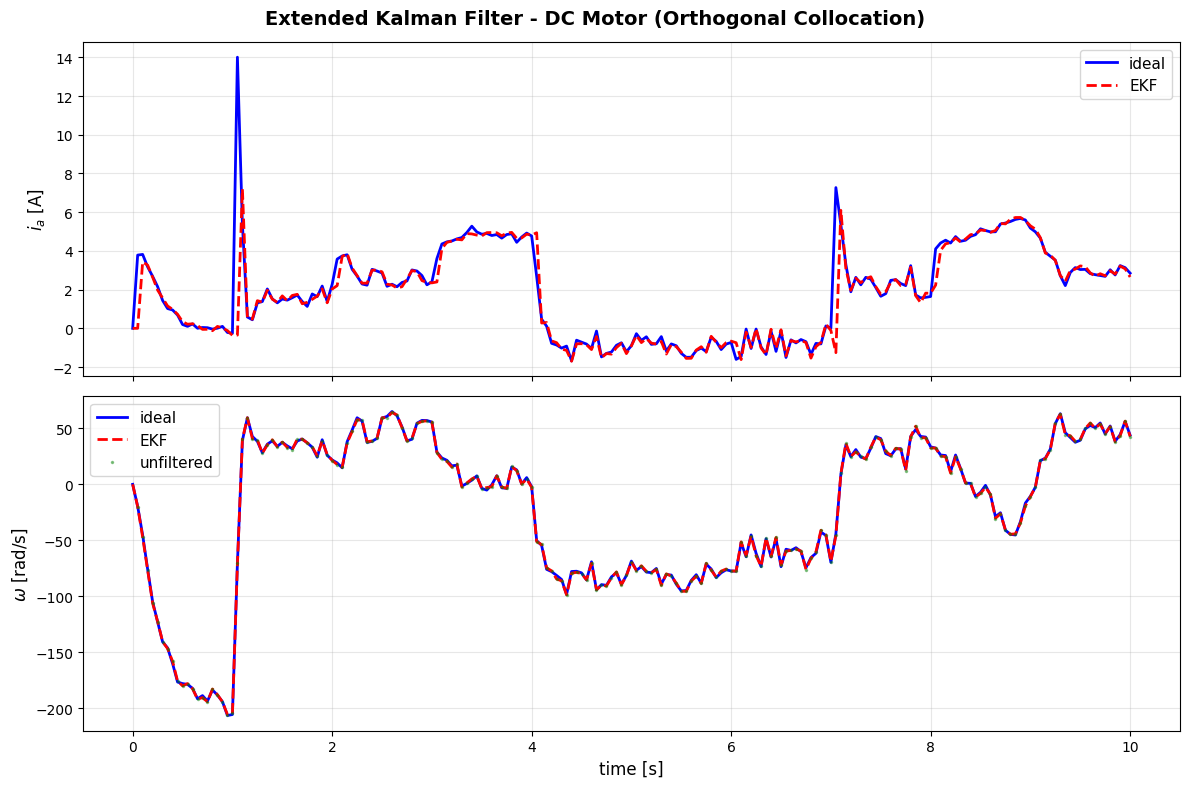

Estimation Performance Metrics:
RMSE (ia):         1.2463 A
RMSE (omega):      1.0019 rad/s
Max error (ia):    14.3554 A
Max error (omega): 3.2033 rad/s


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from casadi import *

# ----------------------------------------------------------------------------
# System Parameters & Setup
# ----------------------------------------------------------------------------
Ra = 12.345      # Armature resistance [Ω]
La = 0.314       # Armature inductance [H]
km = 0.253       # Motor back-emf constant [Nm/A²]
J = 0.00441      # Total inertia [Nm·s²]
B = 0.00732      # Viscous friction coefficient [Nms]
ua = 60.0        # Constant armature voltage [V]
tau_l = 1.47     # Load torque [Nm]
dt = 0.05        # Sampling time [s]

# Noise statistics
var_v = 1.0      # Measurement noise variance
var_w1 = 0.01    # Process noise variance for ia
var_w2 = 100.0   # Process noise variance for omega

nx = 2
nu = 1
ny = 1
d = 3  # Degree of interpolating polynomial (Radau collocation)

# ----------------------------------------------------------------------------
# Orthogonal Collocation Setup & Dynamics
# ----------------------------------------------------------------------------

x = SX.sym("x", nx)
u = SX.sym("u", nu)

ia = x[0]
omega = x[1]
u_field = u[0]

# Continuous dynamics (ODE)
dia_dt = -Ra/La * ia - km/La * omega * u_field + ua/La
domega_dt = -B/J * omega + km/J * ia * u_field - tau_l/J
f_continuous = Function('f', [x, u], [vertcat(dia_dt, domega_dt)])

# Collocation coefficients (Radau)
tau_root = [0] + collocation_points(d, 'radau')
C = np.zeros((d+1, d+1))
D = np.zeros(d+1)
B_quad = np.zeros(d+1)

for j in range(d+1):
    p = np.poly1d([1])
    for r in range(d+1):
        if r != j:
            p *= np.poly1d([1, -tau_root[r]]) / (tau_root[j] - tau_root[r])
    
    D[j] = p(1.0)
    pder = np.polyder(p)
    for r in range(d+1):
        C[j, r] = pder(tau_root[r])
    pint = np.polyint(p)
    B_quad[j] = pint(1.0)

def build_collocation_integrator():
    x_sym = SX.sym('x', nx)
    u_sym = SX.sym('u', nu)
    
    x_c = [SX.sym('x_c_' + str(j), nx) for j in range(d)]
    
    eq = []
    for j in range(1, d+1):
        xp_j = C[0, j] * x_sym
        for r in range(d):
            xp_j += C[r+1, j] * x_c[r]
        
        f_j = f_continuous(x_c[j-1], u_sym)
        eq.append(dt * f_j - xp_j)
    
    eq = vertcat(*eq)
    x_c_vec = vertcat(*x_c)
    
    # Implicit rootfinding
    rfp = Function('rfp', [x_c_vec, x_sym, u_sym], [eq])
    ifcn = rootfinder('ifcn', 'newton', rfp)
    x_c_sol = ifcn(SX(), x_sym, u_sym)
    x_c_sol_split = vertsplit(x_c_sol, nx)
    
    # Continuity equation
    x_next = D[0] * x_sym
    for j in range(d):
        x_next += D[j+1] * x_c_sol_split[j]
    
    A_tilde = jacobian(x_next, x_sym)
    
    F = Function('F', [x_sym, u_sym], [x_next], ['x', 'u'], ['x_next'])
    A_fun = Function('A_fun', [x_sym, u_sym], [A_tilde], ['x', 'u'], ['A'])
    
    return F, A_fun

system, A_fun = build_collocation_integrator()

# Measurement
y_k = x[1]
measurement = Function('measurement', [x], [y_k])
C_fun = Function('C_fun', [x], [jacobian(y_k, x)])

# ----------------------------------------------------------------------------
# EKF Implementation
# ----------------------------------------------------------------------------

def discrete_EKF_filter(x0, x0_observer, P_0, Q, R, N_sim, u_inputs):
    x_data = [x0]
    x_hat_data = [x0_observer]
    y_measured = []
    
    std_x = np.sqrt(Q.diagonal()).reshape(nx, 1)
    std_y = np.sqrt(R)
    
    for k in range(N_sim):
        u_k = u_inputs[k].reshape(nu, 1)
        
        # --- Correction Step ---
        C_k = C_fun(x0_observer).full()
        
        S = C_k @ P_0 @ C_k.T + R
        L = P_0 @ C_k.T @ np.linalg.inv(S)
        
        # Simulation
        wx = np.random.normal(0, std_x).reshape(nx, 1)
        wy = np.random.normal(0, std_y)
        x0 = system(x0, u_k).full() + wx
        y = measurement(x0).full() + wy
        
        # Update
        innovation = y - measurement(x0_observer).full()
        x0_observer = x0_observer + L @ innovation
        P_0 = (np.eye(nx) - L @ C_k) @ P_0
        
        x_data.append(x0)
        x_hat_data.append(x0_observer)
        y_measured.append(y)
        
        # --- Prediction Step ---
        x0_observer = system(x0_observer, u_k).full()
        A_k = A_fun(x0_observer, u_k).full()
        P_0 = A_k @ P_0 @ A_k.T + Q

    x_data = np.concatenate(x_data, axis=1)
    x_hat_data = np.concatenate(x_hat_data, axis=1)
    y_measured = np.array(y_measured).reshape(1, -1)
    
    return x_data, x_hat_data, y_measured

# ----------------------------------------------------------------------------
# Visualization & Helpers
# ----------------------------------------------------------------------------

def visualize(x_data, x_hat_data, y_measured, time):
    fig, ax = plt.subplots(2, 1, figsize=(12, 8))
    fig.suptitle('Extended Kalman Filter - DC Motor (Orthogonal Collocation)', 
                 fontsize=14, fontweight='bold')
    
    ax[0].plot(time, x_data[0, :], 'b-', linewidth=2, label='ideal')
    ax[0].plot(time, x_hat_data[0, :], 'r--', linewidth=2, label='EKF')
    ax[0].set_ylabel('$i_a$ [A]', fontsize=12)
    ax[0].legend(fontsize=11, loc='best')
    ax[0].grid(True, alpha=0.3)
    ax[0].set_xticklabels([])
    
    ax[1].plot(time, x_data[1, :], 'b-', linewidth=2, label='ideal')
    ax[1].plot(time, x_hat_data[1, :], 'r--', linewidth=2, label='EKF')
    ax[1].plot(time[1:], y_measured[0, :], 'g.', markersize=3, 
               alpha=0.4, label='unfiltered')
    ax[1].set_ylabel('$\omega$ [rad/s]', fontsize=12)
    ax[1].set_xlabel('time [s]', fontsize=12)
    ax[1].legend(fontsize=11, loc='best')
    ax[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('ekf_results_collocation.png', dpi=150, bbox_inches='tight')
    plt.show()

def generate_random_step_inputs(N_sim, u_min=-5, u_max=5):
    u_inputs = np.zeros(N_sim)
    step_duration = int(1.0 / dt)
    
    for i in range(0, N_sim, step_duration):
        u_step = np.random.uniform(u_min, u_max)
        u_inputs[i:min(i+step_duration, N_sim)] = u_step
    
    return u_inputs

# ----------------------------------------------------------------------------
# Main Execution
# ----------------------------------------------------------------------------

if __name__ == "__main__":
    np.random.seed(42)
    
    t_sim = 10.0
    N_sim = int(t_sim / dt)
    time = np.arange(N_sim + 1) * dt
    
    x0 = np.array([0.0, 0.0]).reshape([-1, 1])
    x0_observer = np.array([0.0, 0.0]).reshape([-1, 1])
    
    u_inputs = generate_random_step_inputs(N_sim, u_min=-5, u_max=5)
    
    Q = np.diag([var_w1, var_w2])
    R = np.array([[var_v]])
    P_0 = np.diag([1.0, 100.0])

    x_data, x_hat_data, y_measured = discrete_EKF_filter(
        x0, x0_observer, P_0, Q, R, N_sim, u_inputs
    )
    
    visualize(x_data, x_hat_data, y_measured, time)
    
    error_ia = x_data[0, :] - x_hat_data[0, :]
    error_omega = x_data[1, :] - x_hat_data[1, :]
    
    print("="*70)
    print("Estimation Performance Metrics:")
    print("="*70)
    print(f"RMSE (ia):         {np.sqrt(np.mean(error_ia**2)):.4f} A")
    print(f"RMSE (omega):      {np.sqrt(np.mean(error_omega**2)):.4f} rad/s")
    print(f"Max error (ia):    {np.max(np.abs(error_ia)):.4f} A")
    print(f"Max error (omega): {np.max(np.abs(error_omega)):.4f} rad/s")
    print("="*70)

<h3>Heun's Method:</h3>

<p>
    In the context of simulating dynamic systems such as a DC motor, numerical integration is required to convert continuous-time differential equations into a discrete-time format. <strong>Heun's Method</strong> serves as an advancement over the basic Euler approach by implementing a second-order accurate scheme.
</p>

<p>
    The methodology operates through a two-step process designed to minimize the linearization errors inherent in simpler models:
</p>

<ul>
    <li><strong>The Prediction Step:</strong> The algorithm first calculates an intermediate state estimate by projecting the current slope across the entire time step (Δt), similar to the standard Euler method.</li>
    <li><strong>The Correction Step:</strong> The algorithm then evaluates the slope at this predicted future state. By taking the arithmetic mean of the initial slope and the predicted slope, it produces a more representative gradient for the interval.</li>
</ul>

<p>
    By utilizing this averaged gradient to update the system state, Heun's Method effectively accounts for the curvature of the system's trajectory. This results in a superior approximation of the underlying physics compared to the Forward Euler method, providing a robust balance between computational efficiency and numerical precision.
</p>

<p>
    <strong>The Mathematical Update Rule:</strong><br>
    Predictor: <em>x_pred = x(k) + Δt * f(x(k), u(k))</em><br>
    Corrector: <em>x(k+1) = x(k) + (Δt / 2) * [f(x(k), u(k)) + f(x_pred, u(k))]</em>
</p>

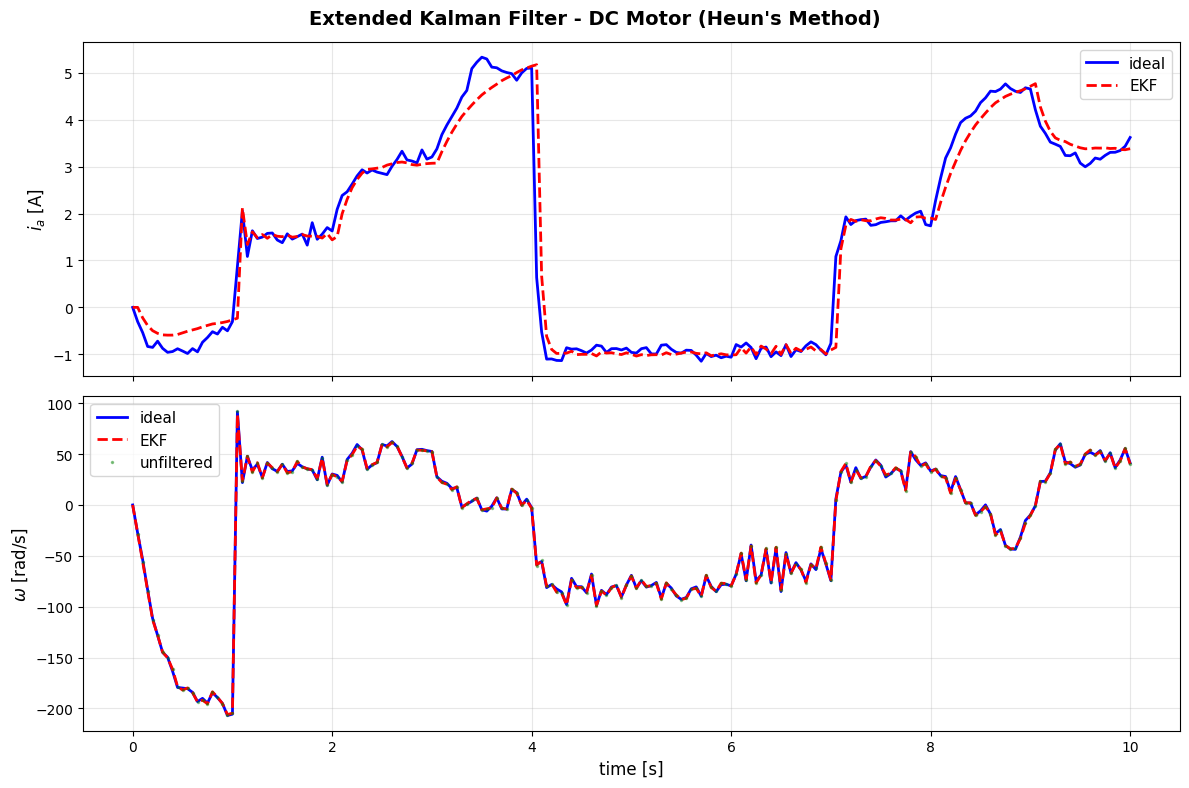

Estimation Performance Metrics:
RMSE (ia):         0.4405 A
RMSE (omega):      1.0238 rad/s
Max error (ia):    4.5366 A
Max error (omega): 3.2011 rad/s


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from casadi import *

# ----------------------------------------------------------------------------
# System Parameters & Setup
# ----------------------------------------------------------------------------
Ra = 12.345      # Armature resistance [Ω]
La = 0.314       # Armature inductance [H]
km = 0.253       # Motor back-emf constant [Nm/A²]
J = 0.00441      # Total inertia [Nm·s²]
B = 0.00732      # Viscous friction coefficient [Nms]
ua = 60.0        # Constant armature voltage [V]
tau_l = 1.47     # Load torque [Nm]
dt = 0.05        # Sampling time [s]

# Noise statistics
var_v = 1.0      # Measurement noise variance
var_w1 = 0.01    # Process noise variance for ia
var_w2 = 100.0   # Process noise variance for omega

nx = 2
nu = 1
ny = 1

# ----------------------------------------------------------------------------
# System Dynamics & Heun's Discretization
# ----------------------------------------------------------------------------

x = SX.sym("x", nx)
u = SX.sym("u", nu)

ia = x[0]
omega = x[1]
u_field = u[0]

# Continuous dynamics (ODE)
dia_dt = -Ra/La * ia - km/La * omega * u_field + ua/La
domega_dt = -B/J * omega + km/J * ia * u_field - tau_l/J
f_continuous = Function('f', [x, u], [vertcat(dia_dt, domega_dt)])

# Discretization using Heun's Method (RK2)
k1 = f_continuous(x, u)
x_pred = x + dt * k1
k2 = f_continuous(x_pred, u)
x_next = x + dt/2 * (k1 + k2)

system = Function('system', [x, u], [x_next])

# Measurement equation
y_k = x[1]
measurement = Function('measurement', [x], [y_k])

# Jacobians
A_tilde = jacobian(x_next, x)
A_fun = Function('A_fun', [x, u], [A_tilde])

C_tilde = jacobian(y_k, x)
C_fun = Function('C_fun', [x], [C_tilde])

# ----------------------------------------------------------------------------
# EKF Implementation
# ----------------------------------------------------------------------------

def discrete_EKF_filter(x0, x0_observer, P_0, Q, R, N_sim, u_inputs):
    x_data = [x0]
    x_hat_data = [x0_observer]
    y_measured = []
    
    std_x = np.sqrt(Q.diagonal()).reshape(nx, 1)
    std_y = np.sqrt(R)
    
    for k in range(N_sim):
        u_k = u_inputs[k].reshape(nu, 1)
        
        # --- Correction Step ---
        C_k = C_fun(x0_observer).full()
        
        S = C_k @ P_0 @ C_k.T + R
        L = P_0 @ C_k.T @ np.linalg.inv(S)
        
        # Simulation
        wx = np.random.normal(0, std_x).reshape(nx, 1)
        wy = np.random.normal(0, std_y)
        x0 = system(x0, u_k).full() + wx
        y = measurement(x0).full() + wy
        
        # Update
        innovation = y - measurement(x0_observer).full()
        x0_observer = x0_observer + L @ innovation
        P_0 = (np.eye(nx) - L @ C_k) @ P_0
        
        x_data.append(x0)
        x_hat_data.append(x0_observer)
        y_measured.append(y)
        
        # --- Prediction Step ---
        x0_observer = system(x0_observer, u_k).full()
        A_k = A_fun(x0_observer, u_k).full()
        P_0 = A_k @ P_0 @ A_k.T + Q

    x_data = np.concatenate(x_data, axis=1)
    x_hat_data = np.concatenate(x_hat_data, axis=1)
    y_measured = np.array(y_measured).reshape(1, -1)
    
    return x_data, x_hat_data, y_measured

# ----------------------------------------------------------------------------
# Visualization & Helpers
# ----------------------------------------------------------------------------

def visualize(x_data, x_hat_data, y_measured, time):
    fig, ax = plt.subplots(2, 1, figsize=(12, 8))
    fig.suptitle("Extended Kalman Filter - DC Motor (Heun's Method)", 
                 fontsize=14, fontweight='bold')
    
    ax[0].plot(time, x_data[0, :], 'b-', linewidth=2, label='ideal')
    ax[0].plot(time, x_hat_data[0, :], 'r--', linewidth=2, label='EKF')
    ax[0].set_ylabel('$i_a$ [A]', fontsize=12)
    ax[0].legend(fontsize=11, loc='best')
    ax[0].grid(True, alpha=0.3)
    ax[0].set_xticklabels([])
    
    ax[1].plot(time, x_data[1, :], 'b-', linewidth=2, label='ideal')
    ax[1].plot(time, x_hat_data[1, :], 'r--', linewidth=2, label='EKF')
    ax[1].plot(time[1:], y_measured[0, :], 'g.', markersize=3, 
               alpha=0.4, label='unfiltered')
    ax[1].set_ylabel('$\omega$ [rad/s]', fontsize=12)
    ax[1].set_xlabel('time [s]', fontsize=12)
    ax[1].legend(fontsize=11, loc='best')
    ax[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('ekf_results_heun.png', dpi=150, bbox_inches='tight')
    plt.show()

def generate_random_step_inputs(N_sim, u_min=-5, u_max=5):
    u_inputs = np.zeros(N_sim)
    step_duration = int(1.0 / dt)
    
    for i in range(0, N_sim, step_duration):
        u_step = np.random.uniform(u_min, u_max)
        u_inputs[i:min(i+step_duration, N_sim)] = u_step
    
    return u_inputs

# ----------------------------------------------------------------------------
# Main Execution
# ----------------------------------------------------------------------------

if __name__ == "__main__":
    np.random.seed(42)
    
    t_sim = 10.0
    N_sim = int(t_sim / dt)
    time = np.arange(N_sim + 1) * dt
    
    x0 = np.array([0.0, 0.0]).reshape([-1, 1])
    x0_observer = np.array([0.0, 0.0]).reshape([-1, 1])
    
    u_inputs = generate_random_step_inputs(N_sim, u_min=-5, u_max=5)
    
    Q = np.diag([var_w1, var_w2])
    R = np.array([[var_v]])
    P_0 = np.diag([1.0, 100.0])

    x_data, x_hat_data, y_measured = discrete_EKF_filter(
        x0, x0_observer, P_0, Q, R, N_sim, u_inputs
    )
    
    visualize(x_data, x_hat_data, y_measured, time)
    
    error_ia = x_data[0, :] - x_hat_data[0, :]
    error_omega = x_data[1, :] - x_hat_data[1, :]
    
    print("="*70)
    print("Estimation Performance Metrics:")
    print("="*70)
    print(f"RMSE (ia):         {np.sqrt(np.mean(error_ia**2)):.4f} A")
    print(f"RMSE (omega):      {np.sqrt(np.mean(error_omega**2)):.4f} rad/s")
    print(f"Max error (ia):    {np.max(np.abs(error_ia)):.4f} A")
    print(f"Max error (omega): {np.max(np.abs(error_omega)):.4f} rad/s")
    print("="*70)

<h3>Backward Euler Method:</h3>

<p>
    The <strong>Backward Euler Method</strong> is a sophisticated implicit numerical integration technique used to discretize continuous-time systems. While explicit methods project the system's future state using currently known gradients, the Backward Euler approach defines the next state based on the gradient at the destination point.
</p>

<p>
    This method is characterized by several professional-grade advantages in control engineering:
</p>

<ul>
    <li><strong>Implicit Formulation:</strong> Because the future state is an input to its own derivative function, the method requires solving an algebraic equation at each time step. This often involves iterative numerical solvers.</li>
    <li><strong>Numerical Stability:</strong> It is "unconditionally stable," meaning it can handle much larger time steps without the risk of numerical oscillation or divergence, even in systems with high-frequency dynamics.</li>
    <li><strong>Stiffness Handling:</strong> It is the preferred choice for "stiff" differential equations—systems where certain variables change much faster than others—ensuring the simulation remains physically accurate and computationally robust.</li>
</ul>

<p>
    By prioritizing stability and mathematical convergence, the Backward Euler Method provides a reliable foundation for simulating the behavior of electrical machines and complex mechanical loads where sudden transients are common.
</p>

<p>
    <strong>The Mathematical Update Rule:</strong><br>
    x(k+1) = x(k) + Δt * f(x(k+1), u(k+1))
</p>

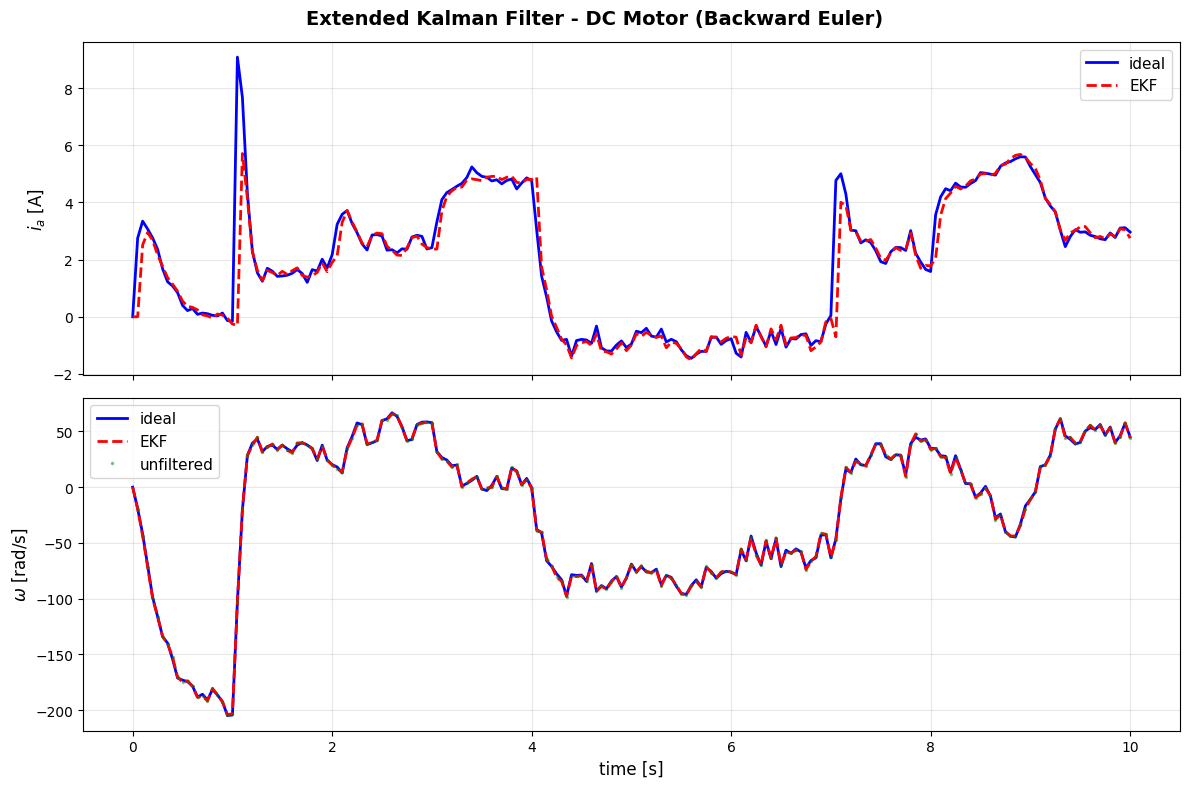

Estimation Performance Metrics:
RMSE (ia):         0.8428 A
RMSE (omega):      1.0031 rad/s
Max error (ia):    9.3868 A
Max error (omega): 3.2024 rad/s


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from casadi import *

# ----------------------------------------------------------------------------
# System Parameters & Setup
# ----------------------------------------------------------------------------
Ra = 12.345      # Armature resistance [Ω]
La = 0.314       # Armature inductance [H]
km = 0.253       # Motor back-emf constant [Nm/A²]
J = 0.00441      # Total inertia [Nm·s²]
B = 0.00732      # Viscous friction coefficient [Nms]
ua = 60.0        # Constant armature voltage [V]
tau_l = 1.47     # Load torque [Nm]
dt = 0.05        # Sampling time [s]

# Noise statistics
var_v = 1.0      # Measurement noise variance
var_w1 = 0.01    # Process noise variance for ia
var_w2 = 100.0   # Process noise variance for omega

nx = 2
nu = 1
ny = 1

# ----------------------------------------------------------------------------
# System Dynamics & Backward Euler Discretization
# ----------------------------------------------------------------------------

x = SX.sym("x", nx)
u = SX.sym("u", nu)

ia = x[0]
omega = x[1]
u_field = u[0]

# Continuous dynamics (ODE)
dia_dt = -Ra/La * ia - km/La * omega * u_field + ua/La
domega_dt = -B/J * omega + km/J * ia * u_field - tau_l/J
f_continuous = Function('f', [x, u], [vertcat(dia_dt, domega_dt)])

# Backward Euler (Implicit) Discretization
x_k = SX.sym('x_k', nx)
x_kp1 = SX.sym('x_kp1', nx)
u_k = SX.sym('u_k', nu)

# Implicit equation: g = x_{k+1} - x_k - dt * f(x_{k+1}, u_k) = 0
g = x_kp1 - x_k - dt * f_continuous(x_kp1, u_k)

# Root-finding problem
rootfinder_prob = {'x': x_kp1, 'p': vertcat(x_k, u_k), 'g': g}
solver = rootfinder('solver', 'newton', rootfinder_prob)

def create_backward_euler_function():
    x_current = SX.sym('x_current', nx)
    u_current = SX.sym('u_current', nu)
    x_next_sol = solver(x0=x_current, p=vertcat(x_current, u_current))
    return Function('F', [x_current, u_current], [x_next_sol['x']], ['x', 'u'], ['x_next'])

system = create_backward_euler_function()

# Measurement equation
y_k = x[1]
measurement = Function('measurement', [x], [y_k])

# Jacobians
# For implicit method, we differentiate the solved function
x_sym = SX.sym('x_sym', nx)
u_sym = SX.sym('u_sym', nu)
A_jac = jacobian(system(x_sym, u_sym), x_sym)
A_fun = Function('A_fun', [x_sym, u_sym], [A_jac])

C_tilde = jacobian(y_k, x)
C_fun = Function('C_fun', [x], [C_tilde])

# ----------------------------------------------------------------------------
# EKF Implementation
# ----------------------------------------------------------------------------

def discrete_EKF_filter(x0, x0_observer, P_0, Q, R, N_sim, u_inputs):
    x_data = [x0]
    x_hat_data = [x0_observer]
    y_measured = []
    
    std_x = np.sqrt(Q.diagonal()).reshape(nx, 1)
    std_y = np.sqrt(R)
    
    for k in range(N_sim):
        u_k = u_inputs[k].reshape(nu, 1)
        
        # --- Correction Step ---
        C_k = C_fun(x0_observer).full()
        
        S = C_k @ P_0 @ C_k.T + R
        L = P_0 @ C_k.T @ np.linalg.inv(S)
        
        # Simulation
        wx = np.random.normal(0, std_x).reshape(nx, 1)
        wy = np.random.normal(0, std_y)
        x0 = system(x0, u_k).full() + wx
        y = measurement(x0).full() + wy
        
        # Update
        innovation = y - measurement(x0_observer).full()
        x0_observer = x0_observer + L @ innovation
        P_0 = (np.eye(nx) - L @ C_k) @ P_0
        
        x_data.append(x0)
        x_hat_data.append(x0_observer)
        y_measured.append(y)
        
        # --- Prediction Step ---
        x0_observer = system(x0_observer, u_k).full()
        A_k = A_fun(x0_observer, u_k).full()
        P_0 = A_k @ P_0 @ A_k.T + Q

    x_data = np.concatenate(x_data, axis=1)
    x_hat_data = np.concatenate(x_hat_data, axis=1)
    y_measured = np.array(y_measured).reshape(1, -1)
    
    return x_data, x_hat_data, y_measured

# ----------------------------------------------------------------------------
# Visualization & Helpers
# ----------------------------------------------------------------------------

def visualize(x_data, x_hat_data, y_measured, time):
    fig, ax = plt.subplots(2, 1, figsize=(12, 8))
    fig.suptitle("Extended Kalman Filter - DC Motor (Backward Euler)", 
                 fontsize=14, fontweight='bold')
    
    ax[0].plot(time, x_data[0, :], 'b-', linewidth=2, label='ideal')
    ax[0].plot(time, x_hat_data[0, :], 'r--', linewidth=2, label='EKF')
    ax[0].set_ylabel('$i_a$ [A]', fontsize=12)
    ax[0].legend(fontsize=11, loc='best')
    ax[0].grid(True, alpha=0.3)
    ax[0].set_xticklabels([])
    
    ax[1].plot(time, x_data[1, :], 'b-', linewidth=2, label='ideal')
    ax[1].plot(time, x_hat_data[1, :], 'r--', linewidth=2, label='EKF')
    ax[1].plot(time[1:], y_measured[0, :], 'g.', markersize=3, 
               alpha=0.4, label='unfiltered')
    ax[1].set_ylabel('$\omega$ [rad/s]', fontsize=12)
    ax[1].set_xlabel('time [s]', fontsize=12)
    ax[1].legend(fontsize=11, loc='best')
    ax[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('ekf_results_BED.png', dpi=150, bbox_inches='tight')
    plt.show()

def generate_random_step_inputs(N_sim, u_min=-5, u_max=5):
    u_inputs = np.zeros(N_sim)
    step_duration = int(1.0 / dt)
    
    for i in range(0, N_sim, step_duration):
        u_step = np.random.uniform(u_min, u_max)
        u_inputs[i:min(i+step_duration, N_sim)] = u_step
    
    return u_inputs

# ----------------------------------------------------------------------------
# Main Execution
# ----------------------------------------------------------------------------

if __name__ == "__main__":
    np.random.seed(42)
    
    t_sim = 10.0
    N_sim = int(t_sim / dt)
    time = np.arange(N_sim + 1) * dt
    
    x0 = np.array([0.0, 0.0]).reshape([-1, 1])
    x0_observer = np.array([0.0, 0.0]).reshape([-1, 1])
    
    u_inputs = generate_random_step_inputs(N_sim, u_min=-5, u_max=5)
    
    Q = np.diag([var_w1, var_w2])
    R = np.array([[var_v]])
    P_0 = np.diag([1.0, 100.0])

    x_data, x_hat_data, y_measured = discrete_EKF_filter(
        x0, x0_observer, P_0, Q, R, N_sim, u_inputs
    )
    
    visualize(x_data, x_hat_data, y_measured, time)
    
    error_ia = x_data[0, :] - x_hat_data[0, :]
    error_omega = x_data[1, :] - x_hat_data[1, :]
    
    print("="*70)
    print("Estimation Performance Metrics:")
    print("="*70)
    print(f"RMSE (ia):         {np.sqrt(np.mean(error_ia**2)):.4f} A")
    print(f"RMSE (omega):      {np.sqrt(np.mean(error_omega**2)):.4f} rad/s")
    print(f"Max error (ia):    {np.max(np.abs(error_ia)):.4f} A")
    print(f"Max error (omega): {np.max(np.abs(error_omega)):.4f} rad/s")
    print("="*70)

<h3>Tustin's Method:</h3>

<p>
    <strong>Tustin's Method</strong>, also known as the Bilinear Transformation, is a sophisticated numerical technique used to translate continuous-time dynamics into the discrete-time domain. It is widely utilized in the design of digital controllers and filters due to its unique mapping properties.
</p>

<p>
    The methodology is grounded in trapezoidal integration, offering several professional advantages for control system discretization:
</p>

<ul>
    <li><strong>Stability Preservation:</strong> One of the most critical features of Tustin's Method is that it preserves system stability. It maps the left-half of the continuous s-plane entirely into the unit circle of the discrete z-plane, ensuring that a stable continuous plant remains stable after discretization.</li>
    <li><strong>Frequency Domain Accuracy:</strong> By approximating the integral of the system states as a trapezoid rather than a rectangle, this method provides a superior approximation of the system's frequency response compared to simpler methods like Forward or Backward Euler.</li>
    <li><strong>Algebraic Consistency:</strong> The transformation creates a one-to-one mapping between the continuous and discrete domains. While it introduces a phenomenon known as "frequency warping" at high frequencies, this can be compensated for through pre-warping techniques to ensure precise alignment at specific critical frequencies.</li>
</ul>

<p>
    In professional practice, Tustin's Method is often the preferred choice when the objective is to implement a digital version of a continuous-time controller while maintaining the highest possible fidelity to the original system's performance and stability margins.
</p>

<p>
    <strong>The Mathematical Substitution:</strong><br>
    The continuous-time operator <em>s</em> is approximated as: <em>s ≈ (2 / Δt) * [(z - 1) / (z + 1)]</em>
</p>

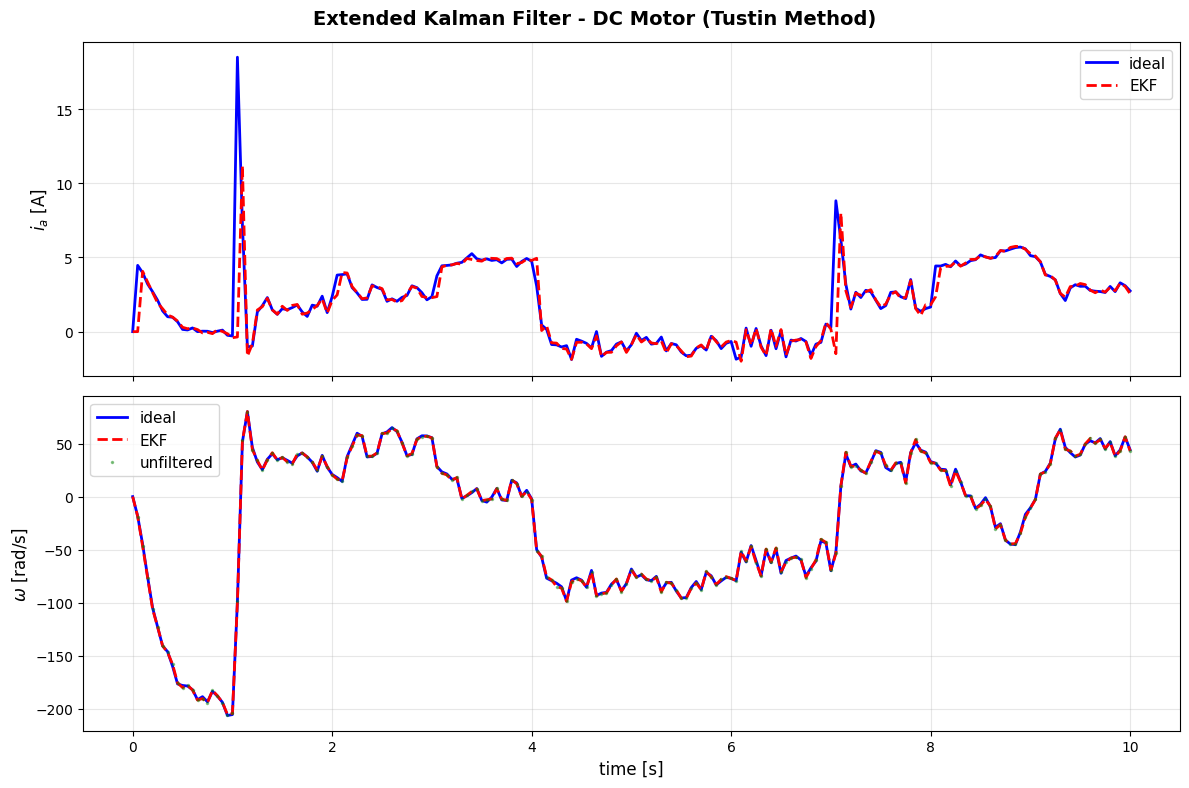

Estimation Performance (Tustin Method):
RMSE (ia):         1.6033 A
RMSE (omega):      0.9991 rad/s
Max error (ia):    18.8627 A
Max error (omega): 3.2036 rad/s


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from casadi import *

# ----------------------------------------------------------------------------
# System Parameters & Setup
# ----------------------------------------------------------------------------
Ra = 12.345      # Armature resistance [Ω]
La = 0.314       # Armature inductance [H]
km = 0.253       # Motor back-emf constant [Nm/A²]
J = 0.00441      # Total inertia [Nm·s²]
B = 0.00732      # Viscous friction coefficient [Nms]
ua = 60.0        # Constant armature voltage [V]
tau_l = 1.47     # Load torque [Nm]
dt = 0.05        # Sampling time [s]

# Noise statistics
var_v = 1.0      # Measurement noise variance
var_w1 = 0.01    # Process noise variance for ia
var_w2 = 100.0   # Process noise variance for omega

nx = 2
nu = 1
ny = 1

# ----------------------------------------------------------------------------
# System Dynamics & Tustin (Trapezoidal) Discretization
# ----------------------------------------------------------------------------

x = SX.sym("x", nx)
u = SX.sym("u", nu)

ia = x[0]
omega = x[1]
u_field = u[0]

# Continuous dynamics (ODE)
dia_dt = -Ra/La * ia - km/La * omega * u_field + ua/La
domega_dt = -B/J * omega + km/J * ia * u_field - tau_l/J
f_continuous = Function('f', [x, u], [vertcat(dia_dt, domega_dt)])

# Tustin (Trapezoidal) Implicit Equation
# x_{k+1} = x_k + dt/2 * [f(x_k, u_k) + f(x_{k+1}, u_k)]
x_k = SX.sym('x_k', nx)
x_kp1 = SX.sym('x_kp1', nx)
u_k = SX.sym('u_k', nu)

g = x_kp1 - x_k - dt/2 * (f_continuous(x_k, u_k) + f_continuous(x_kp1, u_k))

# Implicit Solver
rootfinder_prob = {'x': x_kp1, 'p': vertcat(x_k, u_k), 'g': g}
solver = rootfinder('solver', 'newton', rootfinder_prob)

def create_tustin_function():
    x_current = SX.sym('x_current', nx)
    u_current = SX.sym('u_current', nu)
    x_next_sol = solver(x0=x_current, p=vertcat(x_current, u_current))
    return Function('F', [x_current, u_current], [x_next_sol['x']], ['x', 'u'], ['x_next'])

system = create_tustin_function()

# Measurement equation
y_k = x[1]
measurement = Function('measurement', [x], [y_k])

# Jacobians (Differentiating the discrete mapping)
x_sym = SX.sym('x_sym', nx)
u_sym = SX.sym('u_sym', nu)
A_jac = jacobian(system(x_sym, u_sym), x_sym)
A_fun = Function('A_fun', [x_sym, u_sym], [A_jac])

C_tilde = jacobian(y_k, x)
C_fun = Function('C_fun', [x], [C_tilde])

# ----------------------------------------------------------------------------
# EKF Implementation
# ----------------------------------------------------------------------------

def discrete_EKF_filter(x0, x0_observer, P_0, Q, R, N_sim, u_inputs):
    x_data = [x0]
    x_hat_data = [x0_observer]
    y_measured = []
    
    std_x = np.sqrt(Q.diagonal()).reshape(nx, 1)
    std_y = np.sqrt(R)
    
    for k in range(N_sim):
        u_k = u_inputs[k].reshape(nu, 1)
        
        # --- Correction Step ---
        C_k = C_fun(x0_observer).full()
        
        S = C_k @ P_0 @ C_k.T + R
        L = P_0 @ C_k.T @ np.linalg.inv(S)
        
        # Simulation
        wx = np.random.normal(0, std_x).reshape(nx, 1)
        wy = np.random.normal(0, std_y)
        x0 = system(x0, u_k).full() + wx
        y = measurement(x0).full() + wy
        
        # Update
        innovation = y - measurement(x0_observer).full()
        x0_observer = x0_observer + L @ innovation
        P_0 = (np.eye(nx) - L @ C_k) @ P_0
        
        x_data.append(x0)
        x_hat_data.append(x0_observer)
        y_measured.append(y)
        
        # --- Prediction Step ---
        x0_observer = system(x0_observer, u_k).full()
        A_k = A_fun(x0_observer, u_k).full()
        P_0 = A_k @ P_0 @ A_k.T + Q
    
    x_data = np.concatenate(x_data, axis=1)
    x_hat_data = np.concatenate(x_hat_data, axis=1)
    y_measured = np.array(y_measured).reshape(1, -1)
    
    return x_data, x_hat_data, y_measured

# ----------------------------------------------------------------------------
# Visualization & Helpers
# ----------------------------------------------------------------------------

def visualize(x_data, x_hat_data, y_measured, time):
    fig, ax = plt.subplots(2, 1, figsize=(12, 8))
    fig.suptitle("Extended Kalman Filter - DC Motor (Tustin Method)", 
                 fontsize=14, fontweight='bold')
    
    ax[0].plot(time, x_data[0, :], 'b-', linewidth=2, label='ideal')
    ax[0].plot(time, x_hat_data[0, :], 'r--', linewidth=2, label='EKF')
    ax[0].set_ylabel('$i_a$ [A]', fontsize=12)
    ax[0].legend(fontsize=11, loc='best')
    ax[0].grid(True, alpha=0.3)
    ax[0].set_xticklabels([])
    
    ax[1].plot(time, x_data[1, :], 'b-', linewidth=2, label='ideal')
    ax[1].plot(time, x_hat_data[1, :], 'r--', linewidth=2, label='EKF')
    ax[1].plot(time[1:], y_measured[0, :], 'g.', markersize=3, 
               alpha=0.4, label='unfiltered')
    ax[1].set_ylabel('$\omega$ [rad/s]', fontsize=12)
    ax[1].set_xlabel('time [s]', fontsize=12)
    ax[1].legend(fontsize=11, loc='best')
    ax[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('ekf_results_tustin.png', dpi=150, bbox_inches='tight')
    plt.show()

def generate_random_step_inputs(N_sim, u_min=-5, u_max=5):
    u_inputs = np.zeros(N_sim)
    step_duration = int(1.0 / dt)
    for i in range(0, N_sim, step_duration):
        u_step = np.random.uniform(u_min, u_max)
        u_inputs[i:min(i+step_duration, N_sim)] = u_step
    return u_inputs

# ----------------------------------------------------------------------------
# Main Execution
# ----------------------------------------------------------------------------

if __name__ == "__main__":
    np.random.seed(42)
    
    t_sim = 10.0
    N_sim = int(t_sim / dt)
    time = np.arange(N_sim + 1) * dt
    
    x0 = np.array([0.0, 0.0]).reshape([-1, 1])
    x0_observer = np.array([0.0, 0.0]).reshape([-1, 1])
    
    u_inputs = generate_random_step_inputs(N_sim, u_min=-5, u_max=5)
    
    Q = np.diag([var_w1, var_w2])
    R = np.array([[var_v]])
    P_0 = np.diag([1.0, 100.0])
    
    x_data, x_hat_data, y_measured = discrete_EKF_filter(
        x0, x0_observer, P_0, Q, R, N_sim, u_inputs
    )
    
    visualize(x_data, x_hat_data, y_measured, time)
    
    error_ia = x_data[0, :] - x_hat_data[0, :]
    error_omega = x_data[1, :] - x_hat_data[1, :]
    
    print("="*70)
    print("Estimation Performance (Tustin Method):")
    print("="*70)
    print(f"RMSE (ia):         {np.sqrt(np.mean(error_ia**2)):.4f} A")
    print(f"RMSE (omega):      {np.sqrt(np.mean(error_omega**2)):.4f} rad/s")
    print(f"Max error (ia):    {np.max(np.abs(error_ia)):.4f} A")
    print(f"Max error (omega): {np.max(np.abs(error_omega)):.4f} rad/s")
    print("="*70)

<h3>Zero-Order Hold (ZOH):</h3>

<p>
    The <strong>Zero-Order Hold (ZOH)</strong> method is a critical discretization technique that models the physical behavior of digital control hardware. It serves as the primary bridge between the discrete-time logic of a microprocessor and the continuous-time dynamics of physical systems like a DC motor.
</p>

<p>
    This method is defined by its specific approach to handling control inputs within a sampling period:
</p>

<ul>
    <li><strong>Input Persistence:</strong> ZOH assumes that the input signal remains constant at its sampled value throughout the entire sampling interval (Δt). It does not attempt to interpolate or guess the values between samples.</li>
    <li><strong>Physical Realism:</strong> Because most Digital-to-Analog Converters (DACs) naturally hold a voltage level until the next update command, ZOH is considered the most accurate representation of how a digital controller actually "sees" and interacts with the physical world.</li>
    <li><strong>Exact Solution for Linear Systems:</strong> For linear time-invariant systems, the ZOH discretization provides an exact match at the sampling instances, as it accounts for the system's natural response to a step-like input change.</li>
</ul>

<p>
    In professional control design, utilizing the Zero-Order Hold assumption ensures that the discretized model accounts for the inherent delay and "staircase" nature of digital signals. This is vital for maintaining the performance and stability margins of high-precision systems where the timing of the control action is as important as its magnitude.
</p>

<p>
    <strong>The Mathematical Concept:</strong><br>
    u(t) = u(kΔt) for kΔt ≤ t < (k+1)Δt
</p>

CasADi - 2026-02-04 22:58:13 WARNING("The options 't0', 'tf', 'grid' and 'output_t0' have been deprecated.
The same functionality is provided by providing additional input arguments to the 'integrator' function, in particular:
 * Call integrator(..., t0, tf, options) for a single output time, or
 * Call integrator(..., t0, grid, options) for multiple grid points.
The legacy 'output_t0' option can be emulated by including or excluding 't0' in 'grid'.
Backwards compatibility is provided in this release only.") [.../casadi/core/integrator.cpp:692]


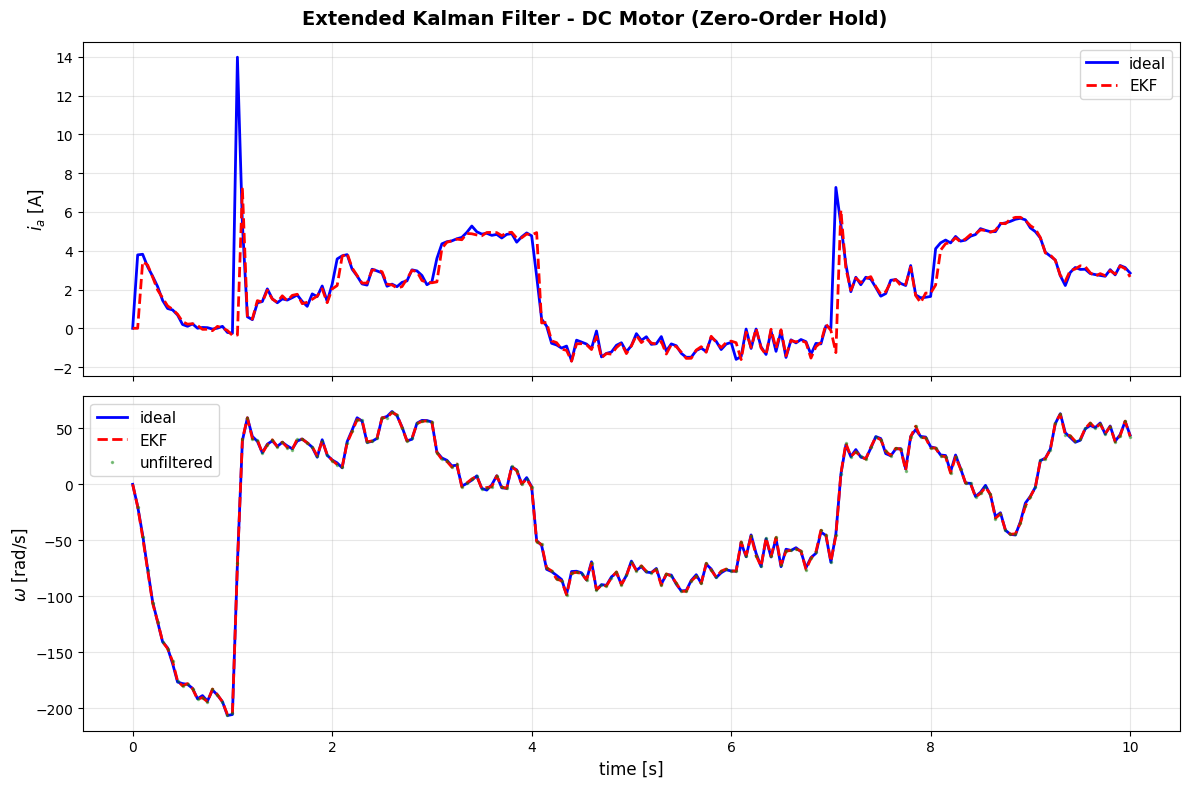

Estimation Performance (ZOH Method):
RMSE (ia):         1.2452 A
RMSE (omega):      1.0019 rad/s
Max error (ia):    14.3377 A
Max error (omega): 3.2033 rad/s


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from casadi import *

# ----------------------------------------------------------------------------
# System Parameters & Setup
# ----------------------------------------------------------------------------
Ra = 12.345      # Armature resistance [Ω]
La = 0.314       # Armature inductance [H]
km = 0.253       # Motor back-emf constant [Nm/A²]
J = 0.00441      # Total inertia [Nm·s²]
B = 0.00732      # Viscous friction coefficient [Nms]
ua = 60.0        # Constant armature voltage [V]
tau_l = 1.47     # Load torque [Nm]
dt = 0.05        # Sampling time [s]

# Noise statistics
var_v = 1.0      # Measurement noise variance
var_w1 = 0.01    # Process noise variance for ia
var_w2 = 100.0   # Process noise variance for omega

nx = 2
nu = 1
ny = 1

# ----------------------------------------------------------------------------
# System Dynamics & ZOH Discretization
# ----------------------------------------------------------------------------

x = SX.sym("x", nx)
u = SX.sym("u", nu)

ia = x[0]
omega = x[1]
u_field = u[0]

# Continuous dynamics (ODE)
dia_dt = -Ra/La * ia - km/La * omega * u_field + ua/La
domega_dt = -B/J * omega + km/J * ia * u_field - tau_l/J
f_continuous = Function('f', [x, u], [vertcat(dia_dt, domega_dt)])

# ZOH Discretization using CasADi Integrator (CVODES)
dae = {'x': x, 'p': u, 'ode': f_continuous(x, u)}
opts = {'tf': dt}
integrator_func = integrator('integrator', 'cvodes', dae, opts)

def create_zoh_function():
    x_sym = SX.sym('x_sym', nx)
    u_sym = SX.sym('u_sym', nu)
    result = integrator_func(x0=x_sym, p=u_sym)
    return Function('F', [x_sym, u_sym], [result['xf']], ['x', 'u'], ['x_next'])

system = create_zoh_function()

# Measurement equation
y_k = x[1]
measurement = Function('measurement', [x], [y_k])

# Jacobians (Differentiating the integrated system)
x_sym = SX.sym('x_sym', nx)
u_sym = SX.sym('u_sym', nu)
A_jac = jacobian(system(x_sym, u_sym), x_sym)
A_fun = Function('A_fun', [x_sym, u_sym], [A_jac])

C_tilde = jacobian(y_k, x)
C_fun = Function('C_fun', [x], [C_tilde])

# ----------------------------------------------------------------------------
# EKF Implementation
# ----------------------------------------------------------------------------

def discrete_EKF_filter(x0, x0_observer, P_0, Q, R, N_sim, u_inputs):
    x_data = [x0]
    x_hat_data = [x0_observer]
    y_measured = []
    
    std_x = np.sqrt(Q.diagonal()).reshape(nx, 1)
    std_y = np.sqrt(R)
    
    for k in range(N_sim):
        u_k = u_inputs[k].reshape(nu, 1)
        
        # --- Correction Step ---
        C_k = C_fun(x0_observer).full()
        
        S = C_k @ P_0 @ C_k.T + R
        L = P_0 @ C_k.T @ np.linalg.inv(S)
        
        # Simulation
        wx = np.random.normal(0, std_x).reshape(nx, 1)
        wy = np.random.normal(0, std_y)
        x0 = system(x0, u_k).full() + wx
        y = measurement(x0).full() + wy
        
        # Update
        innovation = y - measurement(x0_observer).full()
        x0_observer = x0_observer + L @ innovation
        P_0 = (np.eye(nx) - L @ C_k) @ P_0
        
        x_data.append(x0)
        x_hat_data.append(x0_observer)
        y_measured.append(y)
        
        # --- Prediction Step ---
        x0_observer = system(x0_observer, u_k).full()
        A_k = A_fun(x0_observer, u_k).full()
        P_0 = A_k @ P_0 @ A_k.T + Q
    
    x_data = np.concatenate(x_data, axis=1)
    x_hat_data = np.concatenate(x_hat_data, axis=1)
    y_measured = np.array(y_measured).reshape(1, -1)
    
    return x_data, x_hat_data, y_measured

# ----------------------------------------------------------------------------
# Visualization & Helpers
# ----------------------------------------------------------------------------

def visualize(x_data, x_hat_data, y_measured, time):
    fig, ax = plt.subplots(2, 1, figsize=(12, 8))
    fig.suptitle("Extended Kalman Filter - DC Motor (Zero-Order Hold)", 
                 fontsize=14, fontweight='bold')
    
    ax[0].plot(time, x_data[0, :], 'b-', linewidth=2, label='ideal')
    ax[0].plot(time, x_hat_data[0, :], 'r--', linewidth=2, label='EKF')
    ax[0].set_ylabel('$i_a$ [A]', fontsize=12)
    ax[0].legend(fontsize=11, loc='best')
    ax[0].grid(True, alpha=0.3)
    ax[0].set_xticklabels([])
    
    ax[1].plot(time, x_data[1, :], 'b-', linewidth=2, label='ideal')
    ax[1].plot(time, x_hat_data[1, :], 'r--', linewidth=2, label='EKF')
    ax[1].plot(time[1:], y_measured[0, :], 'g.', markersize=3, 
               alpha=0.4, label='unfiltered')
    ax[1].set_ylabel('$\omega$ [rad/s]', fontsize=12)
    ax[1].set_xlabel('time [s]', fontsize=12)
    ax[1].legend(fontsize=11, loc='best')
    ax[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('ekf_results_zoh.png', dpi=150, bbox_inches='tight')
    plt.show()

def generate_random_step_inputs(N_sim, u_min=-5, u_max=5):
    u_inputs = np.zeros(N_sim)
    step_duration = int(1.0 / dt)
    for i in range(0, N_sim, step_duration):
        u_step = np.random.uniform(u_min, u_max)
        u_inputs[i:min(i+step_duration, N_sim)] = u_step
    return u_inputs

# ----------------------------------------------------------------------------
# Main Execution
# ----------------------------------------------------------------------------

if __name__ == "__main__":
    np.random.seed(42)
    
    t_sim = 10.0
    N_sim = int(t_sim / dt)
    time = np.arange(N_sim + 1) * dt
    
    x0 = np.array([0.0, 0.0]).reshape([-1, 1])
    x0_observer = np.array([0.0, 0.0]).reshape([-1, 1])
    
    u_inputs = generate_random_step_inputs(N_sim, u_min=-5, u_max=5)
    
    Q = np.diag([var_w1, var_w2])
    R = np.array([[var_v]])
    P_0 = np.diag([1.0, 100.0])
    
    x_data, x_hat_data, y_measured = discrete_EKF_filter(
        x0, x0_observer, P_0, Q, R, N_sim, u_inputs
    )
    
    visualize(x_data, x_hat_data, y_measured, time)
    
    error_ia = x_data[0, :] - x_hat_data[0, :]
    error_omega = x_data[1, :] - x_hat_data[1, :]
    
    print("="*70)
    print("Estimation Performance (ZOH Method):")
    print("="*70)
    print(f"RMSE (ia):         {np.sqrt(np.mean(error_ia**2)):.4f} A")
    print(f"RMSE (omega):      {np.sqrt(np.mean(error_omega**2)):.4f} rad/s")
    print(f"Max error (ia):    {np.max(np.abs(error_ia)):.4f} A")
    print(f"Max error (omega): {np.max(np.abs(error_omega)):.4f} rad/s")
    print("="*70)

<h3>Comparative Analysis of Numerical Techniques</h3>

<p>
    The table below summarizes the performance of various discretization and estimation techniques applied to the DC motor system. The results compare Root Mean Square Error (RMSE) and Maximum Error for both state variables: armature current (ia) and angular velocity (omega).
</p>

<table border="1">
    <thead>
        <tr>
            <th>Techniques</th>
            <th>RMSE (ia) (A)</th>
            <th>RMSE (omega) (rad/s)</th>
            <th>Max error (ia) (A)</th>
            <th>Max error (omega) (rad/s)</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td>Forward Euler Method</td>
            <td>205.4359</td>
            <td>12.706</td>
            <td>1241.9329</td>
            <td>77.3911</td>
        </tr>
        <tr>
            <td>Backward Euler Method</td>
            <td>0.8428</td>
            <td>1.0031</td>
            <td>9.3868</td>
            <td>3.2024</td>
        </tr>
        <tr>
            <td>Runge-Kutta 4 Method</td>
            <td>1.3961</td>
            <td>1.0014</td>
            <td>16.6155</td>
            <td>3.2033</td>
        </tr>
        <tr>
            <td>Orthogonal Collocation</td>
            <td>1.2463</td>
            <td>1.0019</td>
            <td>14.3554</td>
            <td>3.2033</td>
        </tr>
        <tr>
            <td>Heun’s Method</td>
            <td>0.4405</td>
            <td>1.0238</td>
            <td>4.5366</td>
            <td>3.2011</td>
        </tr>
        <tr>
            <td>Tustin’s Method</td>
            <td>1.6033</td>
            <td>0.9991</td>
            <td>18.8627</td>
            <td>3.2036</td>
        </tr>
        <tr>
            <td>Zero-Order Hold</td>
            <td>1.2452</td>
            <td>1.0019</td>
            <td>14.3377</td>
            <td>3.2033</td>
        </tr>
    </tbody>
</table>

<p>
    <strong>Note:</strong> While the Forward Euler method exhibits significant instability (as evidenced by the high RMSE and Max Error values), the second-order and implicit methods (Heun's, RK4, and Backward Euler) demonstrate superior convergence and precision for this specific nonlinear application.
</p>

<h2>Preliminary Conclusion</h2>

<p> Based on the standalone EKF comparison, <strong>Heun's Method</strong> is currently the strongest candidate. It delivered the lowest RMSE and handled the noise significantly better than the other methods in this open-loop test. </p>

<h3>Why We Are Not Deciding Yet</h3> <p> However, choosing an estimator based solely on standalone performance is risky. The EKF does not operate in a vacuum; it must feed state estimates into a <strong>Model Predictive Controller (MPC)</strong> that utilizes <strong>Orthogonal Collocation</strong>. </p>

<p> We do not yet know how the discretization physics of the EKF (specifically the second-order and implicit behaviors) will interact with the optimization solver of the MPC. A method that looks accurate now might introduce numerical stiffness or instability when the loop is closed. </p>

<h3>Next Steps: The Final Test</h3> <p> To ensure robust control, we will not finalize the EKF algorithm immediately. Instead, we will advance the three most promising "higher-complexity" methods to the next simulation phase: </p> <ul> <li><strong>Heun's Method</strong> (Current Leader)</li> <li><strong>Runge-Kutta 4 (RK4)</strong> (High precision)</li> <li><strong>Backward Euler</strong> (High stability)</li> </ul>

<p> In the upcoming task, we will integrate these directly with the MPC. The final choice will be made based on which method provides the best <strong>closed-loop control performance</strong>, balancing estimation accuracy with computational stability. </p>